# 06. Regularization: Ridge ($L_2$) and Lasso ($L_1$)
### Keeping Linear Regression Stable & Interpretable (Qatar Used Car Context)

In multiple linear regression, our model predicts:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

Standard Linear Regression chooses weights that minimize the Mean Squared Error:

$$\text{MSE}(\mathbf{w}, b) = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2$$

---

### Why do we need Regularization?
When we train a model with multiple features that contain overlapping information (like vehicle age and mileage):
- Standard Linear Regression can sometimes assign **unrealistically large weights** (for example, a huge negative weight on age offset by a large positive weight on mileage).
- The model becomes overly sensitive to small variations in the training data.

---

### The Solution: Regularization
**Regularization** adds a penalty on the size of the weights to the cost function:

$$J_{\text{regularized}}(\mathbf{w}, b) = \text{MSE}(\mathbf{w}, b) + \text{Penalty}(\mathbf{w})$$

1. **Ridge Regression ($L_2$ penalty):** Penalizes $\sum w_j^2$. Shrinks all weights smoothly toward zero, keeping them balanced and moderate.
2. **Lasso Regression ($L_1$ penalty):** Penalizes $\sum |w_j|$. Enforces **sparsity**, driving less important or redundant weights to **exactly zero** (automatic feature selection!).

In [1]:
# Step 1: Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-Learn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

## Section 1: Loading & Inspecting the Qatar Used Cars Dataset

We load `data/qatar_used_cars.csv` with 3 features:
- `age_years`: Vehicle age in years.
- `mileage_km`: Odometer reading in kilometers.
- `engine_size_l`: Engine displacement in Liters.
Target:
- `price_qar`: Selling price in Qatari Riyals.

In [2]:
# Step 2: Load the used car dataset
df = pd.read_csv('data/qatar_used_cars.csv')

print(f"Total car listings: {len(df)}")
display(df.head(6)) if 'display' in globals() else print(df.head(6))

# Check correlation between age and mileage
correlation = df['age_years'].corr(df['mileage_km'])
print(f"\nCorrelation between Vehicle Age and Mileage: {correlation:.3f}")
print("-> High positive correlation! Older cars naturally have higher mileage.")

Total car listings: 24
          model  age_years  mileage_km  engine_size_l  price_qar
0  Toyota Camry          1       18000            2.5      92000
1  Toyota Camry          2       42000            2.5      81000
2  Toyota Camry          3       35000            2.5      76000
3  Toyota Camry          4       78000            2.5      63000
4  Toyota Camry          6      110000            2.5      48000
5  Toyota Camry          8      160000            2.5      34000

Correlation between Vehicle Age and Mileage: 0.989
-> High positive correlation! Older cars naturally have higher mileage.


## Section 2: Train/Test Split & Feature Standardization

### Why MUST we standardize features before Regularization?
In our dataset:
- `age_years` is on a scale of $1$ to $10$.
- `mileage_km` is on a scale of $15,000$ to $210,000$.

The regularization penalties ($\sum w_j^2$ and $\sum |w_j|$) treat all coefficients equally! If features are not on the same scale, the penalty would unfairly punish features with naturally larger numerical values.

Therefore, **we always standardize features to mean = 0 and std = 1 (`StandardScaler`) before applying Ridge or Lasso**.

In [3]:
# Step 3: Train/Test split and feature standardization
feature_cols = ['age_years', 'mileage_km', 'engine_size_l']
X = df[feature_cols].values
y = df['price_qar'].values

# Split data: 75% training, 25% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Standardize features using training statistics
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Standardization complete.")
print(f"Training set: {X_train_s.shape[0]} samples | Testing set: {X_test_s.shape[0]} samples")

Standardization complete.
Training set: 18 samples | Testing set: 6 samples


## Section 3: Standard Linear Regression Baseline

Let's train a standard Linear Regression model on the standardized features and examine the learned coefficients.

In [4]:
# Step 4: Fit standard Linear Regression
model_lr = LinearRegression()
model_lr.fit(X_train_s, y_train)

print("Standard Linear Regression Coefficients:")
print("-" * 50)
for col, coef in zip(feature_cols, model_lr.coef_):
    print(f"  {col:<15}: {coef:+12,.1f} QAR")

Standard Linear Regression Coefficients:
--------------------------------------------------
  age_years      :    -18,740.5 QAR
  mileage_km     :    -19,186.9 QAR
  engine_size_l  :    +47,927.2 QAR


### What did the standard model learn?
- Both **`age_years`** (around **-18,741 QAR**) and **`mileage_km`** (around **-19,187 QAR**) received large negative weights because both capture vehicle wear and usage.
- **`engine_size_l`** (around **+47,927 QAR**) received a large positive weight reflecting vehicle class and performance.
- Because vehicle age and mileage share overlapping information about wear and tear, standard Linear Regression splits the wear effect across both features.

Let's see how **Regularization** adds stability, controls weight sizes, and simplifies the model.


## Section 4: Ridge Regression ($L_2$ Regularization)

**Ridge Regression** adds a penalty proportional to the **sum of squared weights**:

$$J_{\text{Ridge}}(\mathbf{w}, b) = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2 + \alpha \sum_{j=1}^n w_j^2$$

where $\alpha > 0$ is the **regularization strength**:
- The penalty discourages weights from becoming unnecessarily large.
- It smoothly shrinks all weights toward zero, improving stability on unseen test data.

Let's train Ridge with $\alpha = 10.0$ and inspect the learned coefficients.


In [5]:
# Step 5: Fit Ridge Regression (L2)
model_ridge = Ridge(alpha=10.0, random_state=42)
model_ridge.fit(X_train_s, y_train)

print("Ridge Regression (L2, alpha = 10.0) Coefficients:")
print("-" * 50)
for col, coef in zip(feature_cols, model_ridge.coef_):
    print(f"  {col:<15}: {coef:+12,.1f} QAR")

Ridge Regression (L2, alpha = 10.0) Coefficients:
--------------------------------------------------
  age_years      :    -15,190.5 QAR
  mileage_km     :    -14,207.0 QAR
  engine_size_l  :    +30,695.7 QAR


### The Ridge Result:
- Both `age_years` (around **-15,190 QAR**) and `mileage_km` (around **-14,207 QAR**) are smoothly shrunk toward zero.
- `engine_size_l` is also shrunk from **+47,927 QAR** down to **+30,696 QAR**.
- Ridge successfully controls the magnitude of all weights without throwing any feature away.


## Section 5: Lasso Regression ($L_1$ Regularization & Feature Selection)

**Lasso Regression** (Least Absolute Shrinkage and Selection Operator) penalizes the **sum of absolute values**:

$$J_{\text{Lasso}}(\mathbf{w}, b) = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2 + \alpha \sum_{j=1}^n |w_j|$$

### The Unique Power of Lasso:
Because of the sharp geometry of the absolute-value penalty, Lasso pushes less important or redundant coefficients **all the way to EXACT ZERO**!
- It performs **automatic feature selection**, leaving only the most essential predictors.

Let's fit Lasso with $\alpha = 10000.0$ and inspect the coefficients.


In [6]:
# Step 6: Fit Lasso Regression (L1) with alpha=10000.0
model_lasso = Lasso(alpha=10000.0, max_iter=10000, random_state=42)
model_lasso.fit(X_train_s, y_train)

print("--- Lasso Regression Coefficients (alpha=10000.0) ---")
for col, coef in zip(feature_cols, model_lasso.coef_):
    print(f"Weight for {col:15s}: {coef:12,.2f} QAR")
print(f"Intercept:                     {model_lasso.intercept_:12,.2f} QAR")


--- Lasso Regression Coefficients (alpha=10000.0) ---
Weight for age_years      :   -27,678.42 QAR
Weight for mileage_km     :        -0.00 QAR
Weight for engine_size_l  :    37,281.24 QAR
Intercept:                       136,500.00 QAR


### The Lasso Result:
- `mileage_km` is driven to **EXACTLY ZERO (0.00 QAR)**!
- Lasso recognized that since mileage and age share overlapping wear-and-tear information, one of them is redundant. It dropped `mileage_km` completely and kept only `age_years` (**-27,678 QAR**) and `engine_size_l` (**+37,281 QAR**).
- This produces a simpler, more interpretable model with fewer active features!


## Section 6: Visual Comparison of Learned Weights

Let's plot the learned weights side-by-side across all three models:
1. **Standard Linear Regression:** Unconstrained weights.
2. **Ridge ($L_2$):** Balanced, smoothly shrunk weights.
3. **Lasso ($L_1$):** Sparse weights with redundant features zeroed out.

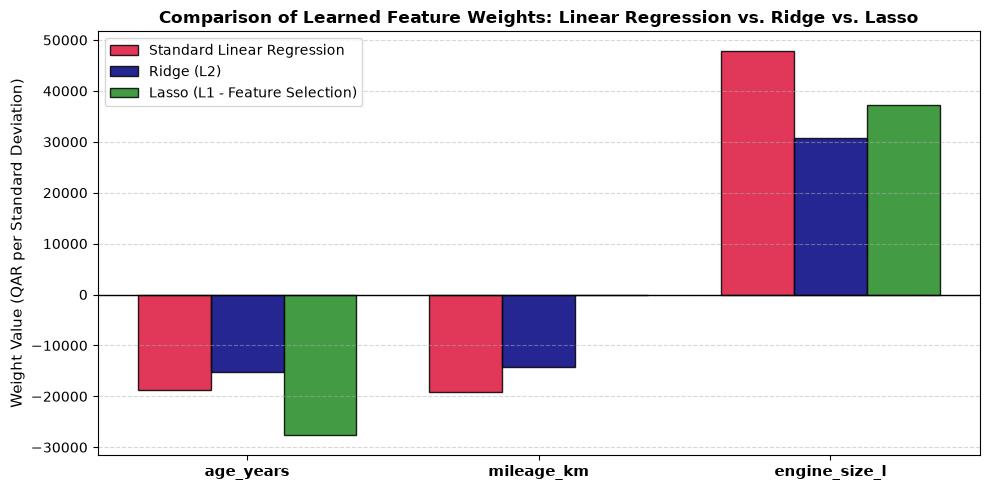

In [7]:
# Step 7: Grouped bar chart comparing coefficients
x_indices = np.arange(len(feature_cols))
bar_width = 0.25

plt.figure(figsize=(10, 5))

# Plot bars for Linear Regression, Ridge, and Lasso
plt.bar(x_indices - bar_width, model_lr.coef_, width=bar_width, color='crimson', 
        label='Standard Linear Regression', edgecolor='black', alpha=0.85)
plt.bar(x_indices, model_ridge.coef_, width=bar_width, color='navy', 
        label='Ridge (L2)', edgecolor='black', alpha=0.85)
plt.bar(x_indices + bar_width, model_lasso.coef_, width=bar_width, color='forestgreen', 
        label='Lasso (L1 - Feature Selection)', edgecolor='black', alpha=0.85)

plt.axhline(0, color='black', linewidth=1)
plt.xticks(x_indices, feature_cols, fontsize=11, fontweight='bold')
plt.title('Comparison of Learned Feature Weights: Linear Regression vs. Ridge vs. Lasso', fontsize=12, fontweight='bold')
plt.ylabel('Weight Value (QAR per Standard Deviation)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.legend()
plt.tight_layout()
plt.show()

## Section 7: Testing Predictive Performance on Unseen Data

Now let's evaluate all three models on the **unseen test set** using $R^2$ and MAE (Mean Absolute Error).

In [8]:
# Step 8: Compare test set metrics
results = []

for name, model in [('Standard Linear Regression', model_lr), 
                    ('Ridge (L2 Regularization)', model_ridge), 
                    ('Lasso (L1 Regularization)', model_lasso)]:
    y_pred = model.predict(X_test_s)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Test MAE (QAR)': f"{mae:,.0f}",
        'Test RMSE (QAR)': f"{rmse:,.0f}",
        'Test R² Score': f"{r2:.3f}"
    })

results_df = pd.DataFrame(results)
display(results_df) if 'display' in globals() else print(results_df.to_string(index=False))

                     Model Test MAE (QAR) Test RMSE (QAR) Test R² Score
Standard Linear Regression         15,773          17,166         0.884
 Ridge (L2 Regularization)         19,145          21,181         0.824
 Lasso (L1 Regularization)         13,864          15,160         0.910


## Section 8: The Regularization Path (How Weights Evolve with $\alpha$)

What happens as we continuously increase the penalty strength $\alpha$?
- In **Ridge**, all coefficients smoothly shrink toward zero, but rarely become exactly zero.
- In **Lasso**, coefficients drop to **exactly zero one by one**, revealing the order of feature importance!

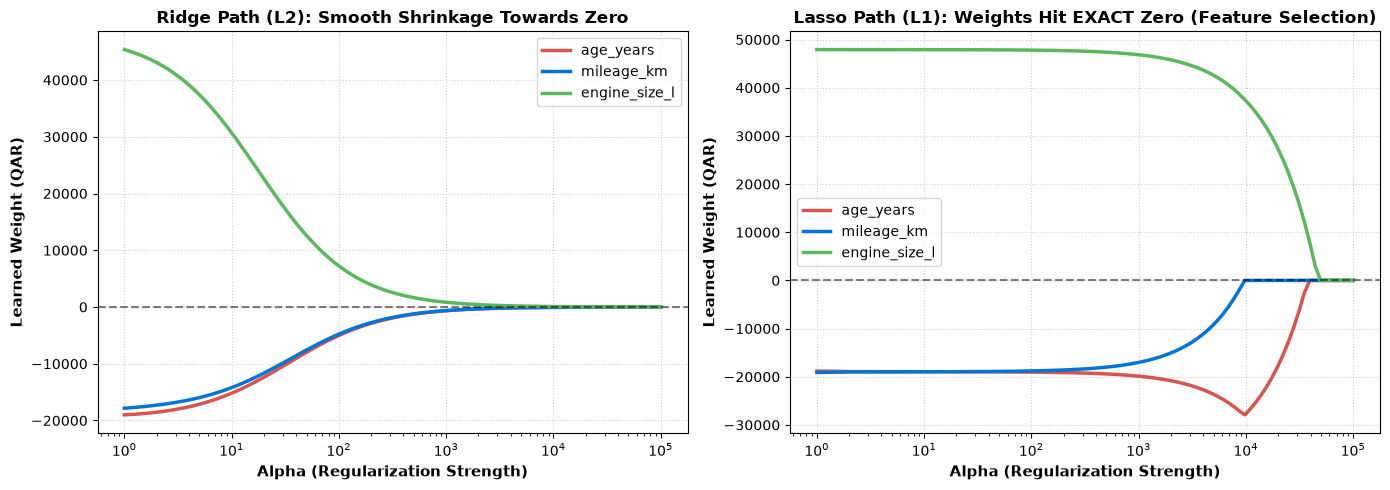

In [9]:
# Step 9: Plotting Regularization Paths
alphas = np.logspace(0, 5, 100)

ridge_coefs = []
lasso_coefs = []

for a in alphas:
    r = Ridge(alpha=a, random_state=42).fit(X_train_s, y_train)
    l = Lasso(alpha=a, max_iter=10000, random_state=42).fit(X_train_s, y_train)
    ridge_coefs.append(r.coef_)
    lasso_coefs.append(l.coef_)

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

colors = ['#d9534f', '#0275d8', '#5cb85c']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Ridge path
for i, col in enumerate(feature_cols):
    ax1.plot(alphas, ridge_coefs[:, i], label=col, color=colors[i], linewidth=2.5)
ax1.axhline(0, color='black', linestyle='--', alpha=0.5)
ax1.set_xscale('log')
ax1.set_xlabel('Alpha (Regularization Strength)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Learned Weight (QAR)', fontsize=11, fontweight='bold')
ax1.set_title('Ridge Path (L2): Smooth Shrinkage Towards Zero', fontsize=12, fontweight='bold')
ax1.legend(loc='best')
ax1.grid(True, linestyle=':', alpha=0.6)

# Lasso path
for i, col in enumerate(feature_cols):
    ax2.plot(alphas, lasso_coefs[:, i], label=col, color=colors[i], linewidth=2.5)
ax2.axhline(0, color='black', linestyle='--', alpha=0.5)
ax2.set_xscale('log')
ax2.set_xlabel('Alpha (Regularization Strength)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Learned Weight (QAR)', fontsize=11, fontweight='bold')
ax2.set_title('Lasso Path (L1): Weights Hit EXACT Zero (Feature Selection)', fontsize=12, fontweight='bold')
ax2.legend(loc='best')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## Section 9: Key Takeaways & Summary

| Aspect | Standard Linear Regression | Ridge Regression ($L_2$) | Lasso Regression ($L_1$) |
| :--- | :--- | :--- | :--- |
| **Penalty Term** | None | $\alpha \sum w_j^2$ | $\alpha \sum |w_j|$ |
| **Coefficient Behavior** | Can become large & unstable with overlapping features | Shrunk smoothly toward zero | Pushed to **exact zero** |
| **Feature Selection?** | No (keeps all features) | No (shrinks all features) | **Yes** (drops redundant features) |
| **Standardization?** | Optional | **Mandatory** | **Mandatory** |
| **Best Used When** | Few clearly independent features | Many features that may overlap | Many features, wanting a simpler model |

---
### Complete Course Curriculum Recap:
- **Notebook 01:** Cost Function & Loss Visualization (Doha rental prices, residuals, MSE divided by $m$).
- **Notebook 02:** Gradient Descent Intuition (Parabola $f(x)=x^2$, step updates, learning rate comparison).
- **Notebook 03:** Univariate Linear Regression from Scratch (NumPy implementation, learning curves, rent prediction).
- **Notebook 04:** Multiple Linear Regression & Feature Scaling (Matrix vectorization, Z-score standardization).
- **Notebook 05:** Linear Regression with Scikit-Learn (Train/test split, MAE, RMSE, $R^2$, residual analysis).
- **Notebook 06:** Regularization: Ridge ($L_2$) & Lasso ($L_1$) (Keeping linear models stable, weight shrinkage, feature selection).